In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [9]:
merged_df = pd.read_csv('Cleaned Data/merged_data.csv')
merged_df.head()

,City,Country,region,short_description,lat,lng,avg_temp_monthly,ideal_durations,budget_level,culture,...,avg_accommodation_cost,avg_transport_cost,Category_x,Best_Time_to_Travel,avg_attraction_fee,num_attractions,Famous Foods,Cultural Significance,Description,Best_Season
0,Milan,Italy,europe,"Chic streets lined with fashion boutiques, his...",45.464194,9.189635,"{'1': {'avg': 3.7, 'max': 7.8, 'min': 0.4}, '2...","['Short trip', 'One week']",Luxury,5,...,NaN,NaN,NaN,NaN,NaN,NaN,"Risotto, Ossobuco, Panettone","A fashion capital known for its shopping, muse...","A modern city with an ancient soul, featuring ...","['Spring', 'Fall']"
1,Yasawa Islands,Fiji,oceania,"Crystal-clear waters, secluded beaches, and vi...",-17.290947,177.125786,"{'1': {'avg': 28, 'max': 30.8, 'min': 25.8}, '...","['Long trip', 'One week']",Luxury,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Whistler,Canada,north america,Snow-capped peaks and lush forests create a se...,50.117190,-122.954302,"{'1': {'avg': -2.5, 'max': 0.4, 'min': -5.5}, ...","['Short trip', 'Weekend', 'One week']",Luxury,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Guanajuato,Mexico,north america,Winding cobblestone streets and colorful facad...,20.987700,-101.000000,"{'1': {'avg': 15.5, 'max': 22.8, 'min': 8.7}, ...","['Weekend', 'One week', 'Short trip']",Mid-range,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Surabaya,Indonesia,asia,Bustling streets filled with the aroma of loca...,-7.245972,112.737827,"{'1': {'avg': 28.1, 'max': 32.5, 'min': 25.5},...","['Short trip', 'Weekend']",Budget,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(merged_df.shape)
print(merged_df.info())

# determine null percentage for each column
(merged_df.isnull().mean() * 100).round(2)

(560, 29)
<class 'pandas.DataFrame'>
RangeIndex: 560 entries, 0 to 559
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   City                    560 non-null    str    
 1   Country                 560 non-null    str    
 2   region                  560 non-null    str    
 3   short_description       560 non-null    str    
 4   lat                     560 non-null    float64
 5   lng                     560 non-null    float64
 6   avg_temp_monthly        560 non-null    str    
 7   ideal_durations         560 non-null    str    
 8   budget_level            560 non-null    str    
 9   culture                 560 non-null    int64  
 10  adventure               560 non-null    int64  
 11  nature                  560 non-null    int64  
 12  beaches                 560 non-null    int64  
 13  nightlife               560 non-null    int64  
 14  cuisine                 560 non-null    int

City                       0.00
Country                    0.00
region                     0.00
short_description          0.00
lat                        0.00
lng                        0.00
avg_temp_monthly           0.00
ideal_durations            0.00
budget_level               0.00
culture                    0.00
adventure                  0.00
nature                     0.00
beaches                    0.00
nightlife                  0.00
cuisine                    0.00
wellness                   0.00
urban                      0.00
seclusion                  0.00
avg_trip_duration         96.25
avg_accommodation_cost    96.25
avg_transport_cost        96.25
Category_x                83.21
Best_Time_to_Travel       83.21
avg_attraction_fee        97.14
num_attractions           97.14
Famous Foods              88.39
Cultural Significance     88.39
Description               90.71
Best_Season               88.39
dtype: float64

In [17]:
category_columns = ['culture', 'adventure', 'nature', 'beaches', 'nightlife', 'cuisine', 'wellness', 'urban', 'seclusion']

# determine score distribution across categories
score_distribution = pd.DataFrame(index=[1,2,3,4,5])

for col in category_columns:
    score_distribution[col] = merged_df[col].value_counts()

score_distribution = score_distribution.fillna(0).sort_index()

score_distribution.index.name = "score"


print(score_distribution)


       culture  adventure  nature  beaches  nightlife  cuisine  wellness  \
score                                                                      
1          0.0        0.0     0.0      221         22      0.0       0.0   
2         20.0      106.0    37.0      119        132     10.0      68.0   
3        173.0      279.0   214.0       81        253    169.0     394.0   
4        238.0      144.0   173.0       64        119    308.0      87.0   
5        129.0       31.0   136.0       75         34     73.0      11.0   

       urban  seclusion  
score                    
1         27         10  
2        118        205  
3        217        135  
4        142        179  
5         56         31  


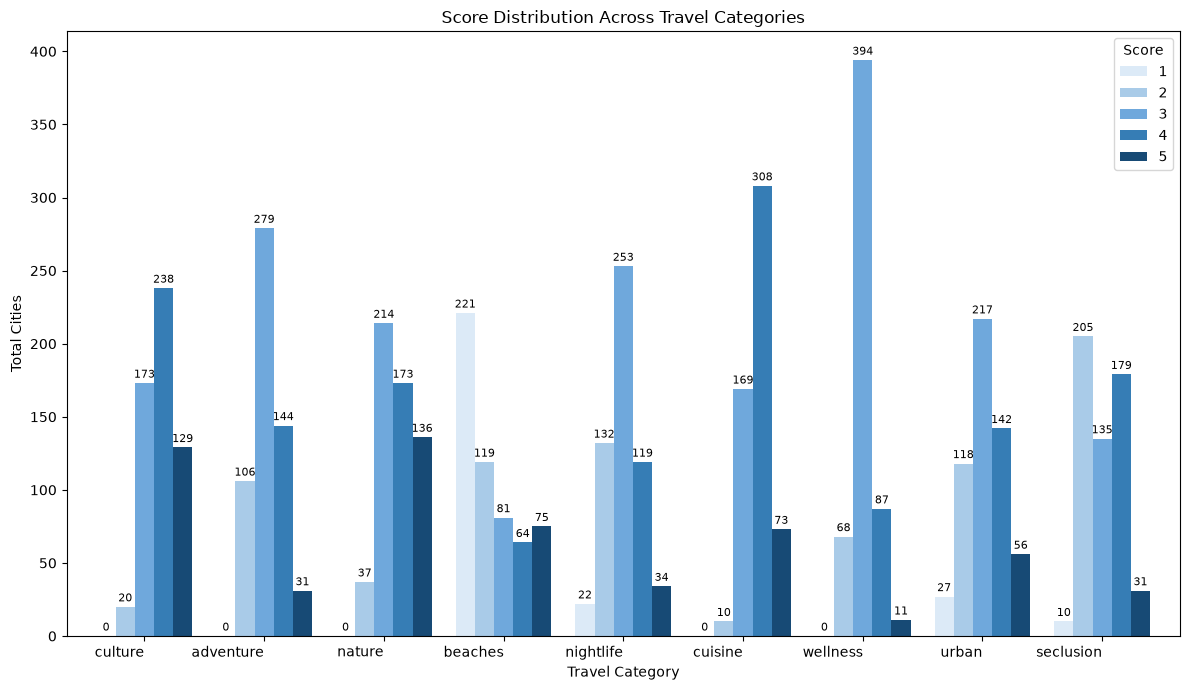

In [25]:
# visualize score distribution

colors = [
    '#DCEAF7',  
    '#A9CBE8',  
    '#6FA8DC',  
    '#367DB5',  
    '#174A75'   
]

ax = score_distribution.T.plot(
    kind = 'bar',
    figsize= (12,7),
    width = 0.8,
    color = colors)

# add value count above each bar
for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=8)

plt.title("Score Distribution Across Travel Categories")
plt.xlabel("Travel Category")
plt.xticks(rotation=0, ha='right')
plt.ylabel("Total Cities")
plt.legend(title='Score')
plt.tight_layout()
plt.show()

In [ ]:
corr = merged_df[category_columns].corr()

            culture  adventure    nature   beaches  nightlife   cuisine  \
culture    1.000000  -0.499020 -0.479116 -0.427770   0.292867  0.555883   
adventure -0.499020   1.000000  0.704513  0.307505  -0.243100 -0.317661   
nature    -0.479116   0.704513  1.000000  0.290630  -0.498231 -0.426750   
beaches   -0.427770   0.307505  0.290630  1.000000   0.098459  0.020401   
nightlife  0.292867  -0.243100 -0.498231  0.098459   1.000000  0.600843   
cuisine    0.555883  -0.317661 -0.426750  0.020401   0.600843  1.000000   
wellness  -0.118368   0.244806  0.264467  0.289171   0.164544  0.206764   
urban      0.486745  -0.448070 -0.607631 -0.214325   0.766809  0.612668   
seclusion -0.388228   0.435114  0.688567  0.139655  -0.726296 -0.544619   

           wellness     urban  seclusion  
culture   -0.118368  0.486745  -0.388228  
adventure  0.244806 -0.448070   0.435114  
nature     0.264467 -0.607631   0.688567  
beaches    0.289171 -0.214325   0.139655  
nightlife  0.164544  0.766809  -0.

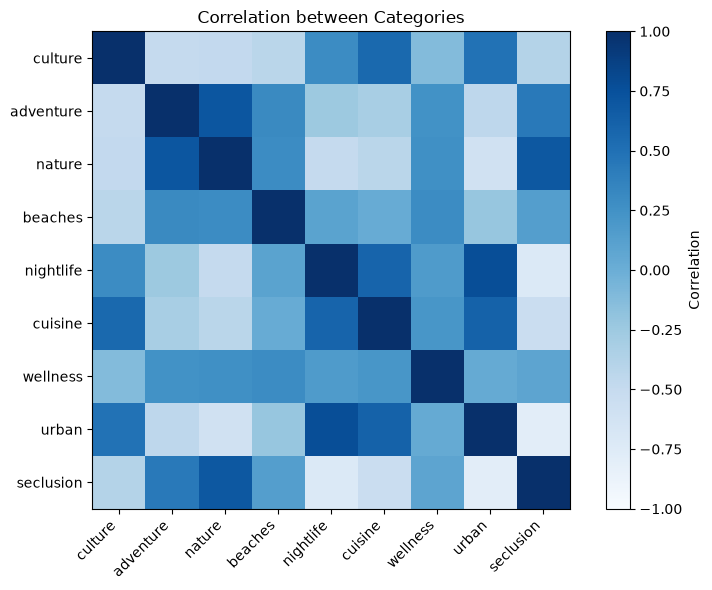

In [32]:
fig, ax = plt.subplots(figsize = (8,6))
im = ax.imshow(corr, cmap='Blues', vmin=-1, vmax=1)

ax.set_xticks(range(len(category_columns)))
ax.set_yticks(range(len(category_columns)))

ax.set_xticklabels(category_columns, rotation=45, ha='right')
ax.set_yticklabels(category_columns)

fig.colorbar(im, label='Correlation')

ax.set_title('Correlation between Categories')
plt.tight_layout()
plt.show()